# Projekt zaliczeniowy

Celem projektu jest analiza zestawu danych związany z oczekiwaną długością życia oraz czynnikami wpływającymi na tę wartość. Zestaw danych zawiera informacje z lat 2000–2015 dla 193 krajów. Opracuj modele predykcyjne i wykorzystaj je do analizy zależności między zmiennymi niezależnymi i wartością oczekiwanej długości życia.

Krok 1: Zrozumienie Danych

Przed rozpoczęciem analizy:

    Przeanalizuj dane, aby zrozumieć strukturę. Przygotuj dane do procesu budowy modeli predykccyjnych.

Krok 2: Modelowanie Predykcyjne

    Wybierz odpowiednią technikę regresji, np. regresję liniową, regresję LASSO/Grzbietową, modele RF czy ANN. Przeprowadź modelowanie predykcyjne, podział adnych na zbiory uczący-testowy.

Krok 3: Analiza Wyników

    Oceń modele na podstawie zestawu testowego (np. R^2, RMSE).
    Wskaż zmienne, które mają największy wpływ na oczekiwaną długość życia.

Krok 4: Wnioski i Rekomendacje

    Na podstawie wyników analizy predykcyjnej, sformułuj wnioski dotyczące czynników wpływających na oczekiwaną długość życia. Zarekomenduj potencjalne kierunki polityki zdrowotnej lub społecznej w celu poprawy oczekiwanej długości życia w krajach o niższych wartościach.

Dodatkowe Wskazówki

Zadanie jest realizowane w grupach 2-4 osobowych. Warunkiem pozytywnego zaliczenia jest opracowanie raportu podsumowującego wyniki pracy oraz kodu źródłowego (notebook) który można uruchomić w celu odtworzenia wykonanych operacji.

Moredel musi cechować się wartości R2 dla przygotowanego zbioru testowego na poziomie co najmniej 0.94 a wartość NRMSE poniżej 6%

Powodzenia w realizacji zadania!

#Dane

**Country:** Nazwa kraju (Kodowane na regiony)

**Year:** Rok, w którym dane zostały zebrane.

**Status:** Undeveloped or Developing status (Kodowane 0/1): Czy kraj jest nierozwinięty czy rozwijający się.

**Life expectancy:** Średnia długość życia wyrażona w latach.

**Adult Mortality:** Wskaźnik śmiertelności dorosłych obu płci (prawdopodobieństwo zgonu między 15 a 60 rokiem życia na 1000 osób).

**infant deaths:** Liczba zgonów niemowląt na 1000 urodzeń.

**Alcohol:** Spożycie alkoholu na jednego dorosłego (15+) w litrach czystego alkoholu.

**percentage expenditure:** Wydatki na zdrowie jako procent produktu krajowego brutto na mieszkańca.

**Hepatitis B:** Odsetek dzieci zaszczepionych przeciwko wirusowemu zapaleniu wątroby typu B (HepB) wśród rocznych dzieci.

**Measles:** Liczba zgłoszonych przypadków odry na 1000 osób.

**BMI:** Średni wskaźnik masy ciała (Body Mass Index) całej populacji.

**under-five deaths:** Liczba zgonów dzieci do 5 roku życia na 1000 urodzeń.

**Polio:** Odsetek dzieci zaszczepionych przeciwko poliomyelitis (Pol3) wśród rocznych dzieci.

**Total expenditure:** Wydatki rządu na zdrowie jako procent całkowitych wydatków rządowych.

**Diphtheria:** Odsetek dzieci zaszczepionych przeciwko błonicy, tężcowi i krztuścowi (DTP3) wśród rocznych dzieci.

**HIV/AIDS:** Liczba zgonów na 1000 żywych urodzeń z powodu HIV/AIDS (wśród dzieci 0-4 lat).

**GDP:** Produkt krajowy brutto na mieszkańca w dolarach amerykańskich.

**Population:** Populacja kraju.

**thinness 1-19 years:** Wskaźnik szczupłości wśród dzieci i młodzieży w wieku 10-19 lat (%).

**thinness 5-9 years:** Wskaźnik szczupłości wśród dzieci w wieku 5-9 lat (%).

**Income composition of resources:** Wskaźnik rozwoju społecznego (Human Development Index) w zakresie składu dochodów (wskaźnik w skali od 0 do 1).

**Schooling:** Liczba lat nauki (w latach).

Wprowadzone kodowanie danych
Kontynent:
    Africa: 1
    Asia: 2
    Europe: 3
    North America: 4
    South America: 5
    Oceania: 6
    Antarctica: 7


Status:
    Developing: 1
    Undeveloped: 0

In [2]:
import numpy as np  # 
import pandas as pd  # 
#from sklearn import *  
import matplotlib.pyplot as plt   
#import ipywidgets as widgets
import seaborn as sns
#from IPython.display import display
import random
from feature_engine.outliers import Winsorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV



In [3]:


train_path = "C:\\Users\\XYZ\\OneDrive\\Pulpit\\projects\\projects\\LE_test_data.csv"
test_path = "C:\\Users\\XYZ\\OneDrive\\Pulpit\\projects\\projects\\LE_train_data.csv"

# Wczytanie danych
train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)

In [3]:
# Podgląd danych
print("Dane uczące:")
print(train_data.head())

print("\nDane testowe:")
print(test_data.head())

Dane uczące:
     Year  Status  Lifeexpectancy  AdultMortality  infantdeaths  Alcohol  \
0  2005.0     1.0            48.6            46.0          45.0     0.42   
1  2011.0     0.0            87.0            59.0           0.0     6.91   
2  2012.0     0.0            76.8           125.0           2.0    10.81   
3  2001.0     1.0            73.0           121.0           2.0     2.76   
4  2006.0     1.0            63.0           242.0          39.0     0.04   

   percentageexpenditure  HepatitisB  Measles   BMI  ...  Totalexpenditure  \
0               8.936065        59.8      2.0  15.4  ...              3.91   
1            3601.287457        82.0      3.0  68.0  ...              9.60   
2             230.040097        97.0     71.0  59.7  ...              6.62   
3              57.103188        61.0     35.0  46.5  ...              7.82   
4               0.000000        78.0   8079.0  34.5  ...              4.82   

   Diphtheria  HIV/AIDS           GDP  Population  thinness1-

In [4]:
print("Unikalne wartości w kolumnie Continent (zbiór uczący):")
print(train_data['Continent'].value_counts().sort_index())

Unikalne wartości w kolumnie Continent (zbiór uczący):
Continent
0.0    167
1.0    138
2.0    115
3.0     65
4.0     26
5.0     22
6.0     10
Name: count, dtype: int64


In [5]:
print("Unikalne wartości w kolumnie Continent (zbiór testowy):")
print(test_data['Continent'].value_counts().sort_index())

Unikalne wartości w kolumnie Continent (zbiór testowy):
Continent
0.0    613
1.0    552
2.0    452
3.0    250
4.0    110
5.0    128
6.0     65
Name: count, dtype: int64


In [6]:
# Mapping statusów i kontynentów
# Przesunięcie wartości w kolumnie Continent o +1
train_data['Continent'] = train_data['Continent'] + 1
test_data['Continent'] = test_data['Continent'] + 1

# Podgląd wyniku
print("Zakodowane kontynenty (zbiór uczący) po przesunięciu:")
print(train_data['Continent'].value_counts().sort_index())

print("\nZakodowane kontynenty (zbiór testowy) po przesunięciu:")
print(test_data['Continent'].value_counts().sort_index())

# Utworzenie mappingu kontynentów (od 1 do 7)
continent_dict = {i: i for i in range(1, 8)}

# Pusty słownik, by nie było błędu NameError
status_dict = {} 

Zakodowane kontynenty (zbiór uczący) po przesunięciu:
Continent
1.0    167
2.0    138
3.0    115
4.0     65
5.0     26
6.0     22
7.0     10
Name: count, dtype: int64

Zakodowane kontynenty (zbiór testowy) po przesunięciu:
Continent
1.0    613
2.0    552
3.0    452
4.0    250
5.0    110
6.0    128
7.0     65
Name: count, dtype: int64


In [7]:
# Wyświetlenie mappingu
print("Mapping kontynentów:")
for continent, code in continent_dict.items():
    print(f"{continent}: {code}")

# Podgląd mappingu
print("\nZakodowane kontynenty (zbiór uczący):")
print(train_data['Continent'].value_counts().sort_index())

print("\nZakodowane kontynenty (zbiór testowy):")
print(test_data['Continent'].value_counts().sort_index())

# Podsumowanie mappingu kontynentów
print("\nZastosowane mappingi kolumn kategorycznych:")
print("Status:", status_dict)
print("Continent:", continent_dict)

Mapping kontynentów:
1: 1
2: 2
3: 3
4: 4
5: 5
6: 6
7: 7

Zakodowane kontynenty (zbiór uczący):
Continent
1.0    167
2.0    138
3.0    115
4.0     65
5.0     26
6.0     22
7.0     10
Name: count, dtype: int64

Zakodowane kontynenty (zbiór testowy):
Continent
1.0    613
2.0    552
3.0    452
4.0    250
5.0    110
6.0    128
7.0     65
Name: count, dtype: int64

Zastosowane mappingi kolumn kategorycznych:
Status: {}
Continent: {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7}


In [8]:
# Zastosowanie do danych uczących i testowych
train_data['Continent'] = train_data['Continent'].map(continent_dict)
test_data['Continent'] = test_data['Continent'].map(continent_dict)

# Wyświetlenie przykładowych wierszy
print("\nPrzykładowe zakodowane kontynenty w zbiorze uczącym:")
print(train_data['Continent'].value_counts().sort_index())

print("\nPrzykładowe zakodowane kontynenty w zbiorze testowym:")
print(test_data['Continent'].value_counts().sort_index())



Przykładowe zakodowane kontynenty w zbiorze uczącym:
Continent
1    167
2    138
3    115
4     65
5     26
6     22
7     10
Name: count, dtype: int64

Przykładowe zakodowane kontynenty w zbiorze testowym:
Continent
1    613
2    552
3    452
4    250
5    110
6    128
7     65
Name: count, dtype: int64


In [9]:
# Sprawdzenie braków danych w zbiorze uczącym
print("\nBraki danych w zbiorze uczącym:")
print(train_data.isnull().sum())

# Sprawdzenie braków danych w zbiorze testowym
print("\nBraki danych w zbiorze testowym:")
print(test_data.isnull().sum())


Braki danych w zbiorze uczącym:
Year                            0
Status                          0
Lifeexpectancy                  0
AdultMortality                  0
infantdeaths                    0
Alcohol                         0
percentageexpenditure           0
HepatitisB                      0
Measles                         0
BMI                             0
under-fivedeaths                0
Polio                           0
Totalexpenditure                0
Diphtheria                      0
HIV/AIDS                        0
GDP                             0
Population                      0
thinness1-19years               0
thinness5-9years                0
Incomecompositionofresources    0
Schooling                       0
Continent                       0
dtype: int64

Braki danych w zbiorze testowym:
Year                            0
Status                          0
Lifeexpectancy                  0
AdultMortality                  0
infantdeaths                    0
Al

In [10]:
# Kodowanie kolumn kategorycznych w zbiorze uczącym
#UWAGA!!!!!!!!!!!!!! Mapowanie statusu jest na odwrót 1-0, 0-1, CZY TO JEST CELOWE?
train_data['Status'], status_mapping = pd.factorize(train_data['Status'])
train_data['Continent'], continent_mapping = pd.factorize(train_data['Continent'])
# 1. Definiujemy jawne mapowania
status_mapping = {0.0: 0, 1.0: 1}
continent_mapping = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6}

# Użycie tych samych mappingów w zbiorze testowym
status_dict = {label: idx for idx, label in enumerate(status_mapping)}
continent_dict = {label: idx for idx, label in enumerate(continent_mapping)}

test_data['Status'] = test_data['Status'].map(status_dict)
test_data['Status'] = test_data['Status'].fillna(-1).astype(int) #Dla bezpieczeństwa mapowania w zbiorze testowym.
test_data['Continent'] = test_data['Continent'].map(continent_dict)
test_data['Continent'] = test_data['Continent'].fillna(-1).astype(int)

# Wyświetlenie mappingów
print("Mappingi kolumn kategorycznych:")
print("Status:", status_dict)
print("Continent:", continent_dict)

Mappingi kolumn kategorycznych:
Status: {0.0: 0, 1.0: 1}
Continent: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6}


In [11]:
# Zmienna docelowa, względem której chcesz sprawdzić korelacje:
zmienna_docelowa = "Lifeexpectancy"


In [12]:
def show_correlation(df, target):
    corr = df.corr(numeric_only=True)[target].drop(target).sort_values(ascending=False)
    df_corr = corr.reset_index()
    df_corr.columns = ["Zmienna", f"Korelacja z {target}"]
    print(df_corr.to_string(index=False))


#  Korelacja zawiera się w przedziale od –1 do 1:
#     Blisko 1: silna dodatnia korelacja – im więcej tej zmiennej, tym dłuższe życie.
#     Blisko –1: silna ujemna korelacja – im więcej tej zmiennej, tym krótsze życie.
#     Blisko 0: brak istotnej zależności.

In [13]:
# Wyświetlenie korelacji
print("Korelacje w zbiorze uczącym:")
show_correlation(train_data, "Lifeexpectancy")

Korelacje w zbiorze uczącym:
                     Zmienna  Korelacja z Lifeexpectancy
                   Schooling                    0.773164
Incomecompositionofresources                    0.714294
                         BMI                    0.548850
                      Status                    0.490922
                       Polio                    0.488800
                  Diphtheria                    0.488359
                         GDP                    0.452375
       percentageexpenditure                    0.425872
                   Continent                    0.415695
                     Alcohol                    0.380086
                  HepatitisB                    0.308162
            Totalexpenditure                    0.265842
                        Year                    0.208213
                  Population                   -0.099003
                     Measles                   -0.180480
                infantdeaths                   -0.273098
  

In [14]:
# Wyświetlenie korelacji
print("Korelacje w zbiorze testowym:")
show_correlation(test_data, "Lifeexpectancy")

Korelacje w zbiorze testowym:
                     Zmienna  Korelacja z Lifeexpectancy
                   Schooling                    0.745019
Incomecompositionofresources                    0.710660
                         BMI                    0.575369
                   Continent                    0.483901
                  Diphtheria                    0.474444
                       Polio                    0.455434
                         GDP                    0.427734
                     Alcohol                    0.410359
       percentageexpenditure                    0.391647
                  HepatitisB                    0.290346
            Totalexpenditure                    0.204377
                        Year                    0.153669
                  Population                   -0.033122
                     Measles                   -0.158641
                infantdeaths                   -0.188125
            under-fivedeaths                   -0.212561
 

In [15]:
# Statystyki opisowe dla zbioru uczącego (średnia, mediana, min, max itd.)
train_data.describe()

,Year,Status,Lifeexpectancy,AdultMortality,infantdeaths,Alcohol,percentageexpenditure,HepatitisB,Measles,BMI,...,Totalexpenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness1-19years,thinness5-9years,Incomecompositionofresources,Schooling,Continent
count,543.000000,543.000000,543.000000,543.000000,543.000000,543.000000,543.000000,543.000000,543.000000,543.000000,...,543.000000,543.000000,543.000000,543.000000,5.430000e+02,543.000000,543.000000,543.000000,543.000000,543.000000
mean,2007.029466,0.193370,69.092081,162.128913,25.399632,4.719098,807.611287,80.225414,2498.909761,36.375322,...,5.848313,81.692449,1.967772,6706.356807,1.094762e+07,4.787661,4.925599,0.623924,12.038711,1.583794
std,4.447631,0.395305,9.850791,123.170965,76.487395,3.996800,1924.666201,24.324012,11679.532453,20.219662,...,2.463192,25.145174,5.593612,13320.180117,3.411650e+07,4.146360,4.307330,0.208939,3.157590,1.497807
min,2000.000000,0.000000,41.500000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.400000,...,0.650000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000,0.000000
25%,2003.000000,0.000000,62.850000,72.000000,0.000000,1.085000,9.837548,75.000000,0.000000,18.050000,...,4.210000,77.000000,0.100000,379.379755,2.913765e+05,1.500000,1.600000,0.493500,10.000000,0.000000
50%,2007.000000,0.000000,72.100000,143.000000,3.000000,3.890000,90.122068,91.000000,18.000000,39.900000,...,5.600000,93.000000,0.100000,1230.144003,1.681495e+06,3.400000,3.400000,0.662000,12.100000,1.000000
75%,2011.000000,0.000000,75.400000,224.500000,20.000000,7.810000,531.576617,96.700000,397.500000,54.750000,...,7.430000,97.000000,0.900000,5315.508470,7.173292e+06,7.250000,7.400000,0.776500,14.400000,2.000000
max,2015.000000,1.000000,89.000000,715.000000,1100.000000,17.870000,15345.490700,99.000000,168107.000000,75.700000,...,17.200000,99.000000,50.600000,89739.711700,4.914484e+08,26.900000,27.600000,0.942000,20.300000,6.000000


In [16]:
test_data.describe()

,Year,Status,Lifeexpectancy,AdultMortality,infantdeaths,Alcohol,percentageexpenditure,HepatitisB,Measles,BMI,...,Totalexpenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness1-19years,thinness5-9years,Incomecompositionofresources,Schooling,Continent
count,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,...,2170.000000,2170.000000,2170.000000,2170.000000,2.170000e+03,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000
mean,2007.033180,0.825346,69.239631,164.474194,32.050691,4.624995,795.369879,80.881014,2501.278802,38.340000,...,5.948029,82.442396,1.782627,6536.669245,1.245834e+07,4.889677,4.892581,0.625750,11.989945,1.694009
std,4.300579,0.379759,9.496080,126.148973,129.441447,4.068294,2089.651964,23.390376,11772.857695,19.787381,...,2.470006,23.376677,5.174124,13715.203129,6.168535e+07,4.519115,4.592347,0.205301,3.180267,1.618647
min,2000.000000,0.000000,36.300000,1.000000,0.000000,0.010000,0.000000,2.000000,0.000000,1.000000,...,0.370000,3.000000,0.100000,3.685949,4.300000e+01,0.100000,0.100000,0.000000,0.000000,0.000000
25%,2003.000000,1.000000,63.500000,73.000000,0.000000,0.870000,10.816084,75.000000,0.000000,19.300000,...,4.300000,78.250000,0.100000,366.784863,3.776358e+05,1.600000,1.500000,0.492000,10.100000,0.000000
50%,2007.000000,1.000000,72.100000,143.000000,3.000000,3.775000,81.080060,91.000000,17.000000,43.650000,...,5.800000,93.000000,0.100000,1214.663924,1.867851e+06,3.300000,3.300000,0.674500,12.300000,1.000000
75%,2011.000000,1.000000,75.675000,226.000000,21.000000,7.757500,477.831914,96.000000,371.500000,56.100000,...,7.460000,97.000000,0.800000,4791.414543,7.859124e+06,7.200000,7.200000,0.773000,14.100000,3.000000
max,2015.000000,1.000000,89.000000,723.000000,1800.000000,17.310000,19479.911610,99.000000,212183.000000,77.100000,...,17.600000,99.000000,50.300000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000,6.000000


In [17]:
# Liczba obserwacji i zmiennych w zbiorach
print(train_data.shape)
print(test_data.shape)

(543, 22)
(2170, 22)


In [18]:
# Definicja zmiennej docelowej (target) oraz zmiennych predykcyjnych (features)
# Zmienna docelowa to 'Lifeexpectancy' - oczekiwana długość życia, którą chcemy przewidzieć
# Zmienne predykcyjne to wszystkie pozostałe kolumny, które będą wykorzystane do budowy modelu
id_variable = ['Lifeexpectancy']
predictors = [var for var in train_data.columns if var not in id_variable]

print(predictors)


['Year', 'Status', 'AdultMortality', 'infantdeaths', 'Alcohol', 'percentageexpenditure', 'HepatitisB', 'Measles', 'BMI', 'under-fivedeaths', 'Polio', 'Totalexpenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness1-19years', 'thinness5-9years', 'Incomecompositionofresources', 'Schooling', 'Continent']


In [19]:
# Pokazuje wszystkie kolumny zbioru podczas podglądu
pd.set_option("display.max_columns", None) 
# Wyświetlenie kilku pierwszych wierszy

test_data.head(10)


,Year,Status,Lifeexpectancy,AdultMortality,infantdeaths,Alcohol,percentageexpenditure,HepatitisB,Measles,BMI,under-fivedeaths,Polio,Totalexpenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness1-19years,thinness5-9years,Incomecompositionofresources,Schooling,Continent
0,2006.0,1,64.1,216.0,17.0,2.03,51.504471,8.0,188.0,14.3,21.0,8.0,4.48,8.0,1.1,539.879153,13474489.0,11.4,11.6,0.483,10.1,1
1,2001.0,1,77.0,178.0,0.0,9.61,81.113560,96.0,0.0,38.2,0.0,96.0,7.67,96.0,0.1,519.958715,872539.2,4.2,4.2,0.000,14.3,3
2,2014.0,1,78.0,23.0,4.0,8.06,5.663849,22.0,0.0,6.7,5.0,45.0,7.10,23.0,0.2,314.658296,45271947.0,2.3,2.4,0.746,15.2,2
3,2012.0,1,72.8,159.0,0.0,6.93,0.000000,96.0,0.0,51.2,0.0,96.0,8.48,96.0,0.1,551.727660,2858563.4,3.5,3.5,0.713,13.3,3
4,2010.0,1,62.3,294.0,2.0,8.85,145.318282,67.0,1.0,33.5,3.0,68.0,3.41,67.0,7.0,8754.113376,16421.0,6.5,6.4,0.660,12.5,0
5,2006.0,1,55.3,388.0,68.0,1.76,52.603854,8.0,1847.0,16.9,104.0,77.0,4.24,8.0,10.3,697.663850,37525.0,8.5,8.4,0.483,9.7,0
6,2002.0,1,46.4,587.0,3.0,5.52,131.042127,88.0,37.0,26.7,4.0,87.0,5.16,85.0,49.9,1324.996228,1893.0,8.6,8.8,0.502,9.2,0
7,2010.0,1,73.7,14.0,10.0,4.72,69.439345,93.0,0.0,52.2,12.0,92.0,5.30,93.0,0.2,522.493191,29373646.0,1.1,1.1,0.708,13.3,5
8,2001.0,0,78.0,96.0,0.0,12.89,7877.336560,86.0,0.0,54.6,0.0,99.0,7.40,99.0,0.1,48179.428500,441525.0,1.0,1.0,0.854,13.4,2
9,2009.0,0,86.0,65.0,1.0,9.23,96.858588,96.0,15.0,58.6,1.0,97.0,1.29,97.0,0.1,519.349000,1653388.0,1.0,0.9,0.906,16.9,2


In [20]:
train_data.head(10)

,Year,Status,Lifeexpectancy,AdultMortality,infantdeaths,Alcohol,percentageexpenditure,HepatitisB,Measles,BMI,under-fivedeaths,Polio,Totalexpenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness1-19years,thinness5-9years,Incomecompositionofresources,Schooling,Continent
0,2005.0,0,48.6,46.0,45.0,0.42,8.936065,59.8,2.0,15.4,79.0,37.0,3.91,25.0,5.2,66.242140,1679.0,1.5,1.4,0.306,5.60,0
1,2011.0,1,87.0,59.0,0.0,6.91,3601.287457,82.0,3.0,68.0,0.0,96.0,9.60,96.0,0.1,22821.847000,416268.0,0.8,0.7,0.826,14.80,1
2,2012.0,1,76.8,125.0,2.0,10.81,230.040097,97.0,71.0,59.7,2.0,95.0,6.62,99.0,0.1,13145.148400,3863164.0,2.0,2.1,0.834,15.30,1
3,2001.0,0,73.0,121.0,2.0,2.76,57.103188,61.0,35.0,46.5,2.0,83.0,7.82,87.0,0.1,733.974142,43864.0,3.0,3.1,0.673,11.70,2
4,2006.0,0,63.0,242.0,39.0,0.04,0.000000,78.0,8079.0,34.5,51.0,78.0,4.82,78.0,0.1,1230.144003,14380790.6,13.9,13.8,0.475,8.70,2
5,2004.0,0,64.2,263.0,1.0,0.96,2.586698,89.0,3.0,16.1,1.0,9.0,4.41,89.0,0.3,197.457880,64282.0,18.0,18.8,0.000,8.80,2
6,2007.0,0,49.9,443.0,61.0,2.58,0.000000,76.0,5.0,23.2,87.0,75.0,6.35,76.0,5.3,276.487432,6537615.0,6.8,6.7,0.407,9.14,0
7,2001.0,1,77.0,89.0,0.0,14.27,4264.579203,93.4,241.0,52.2,0.0,84.0,6.60,84.0,0.1,28223.555280,3866243.0,0.3,0.3,0.857,16.40,1
8,2012.0,0,74.3,154.0,9.0,6.56,801.050465,98.0,5197.0,3.1,11.0,99.0,4.17,99.0,0.1,5859.915622,67843979.0,8.0,8.1,0.729,13.70,2
9,2010.0,0,64.4,233.0,35.0,0.06,0.000000,76.0,510.0,37.2,45.0,77.0,5.17,76.0,0.1,691.551997,9792455.0,13.7,13.7,0.488,8.50,2


In [21]:
# Badamy rozkłady zmiennych

#     Liczba unikalnych wartości
#     Analiza rozkładów zmienne ilościowe - histogramy, wykres ramkowy, statystyki
#     Analiza rozkładów zmienne jakościowe - histogramy, tabela liczności
#     Ocena pod kątem wartości odstających i kategorii o małej liczności


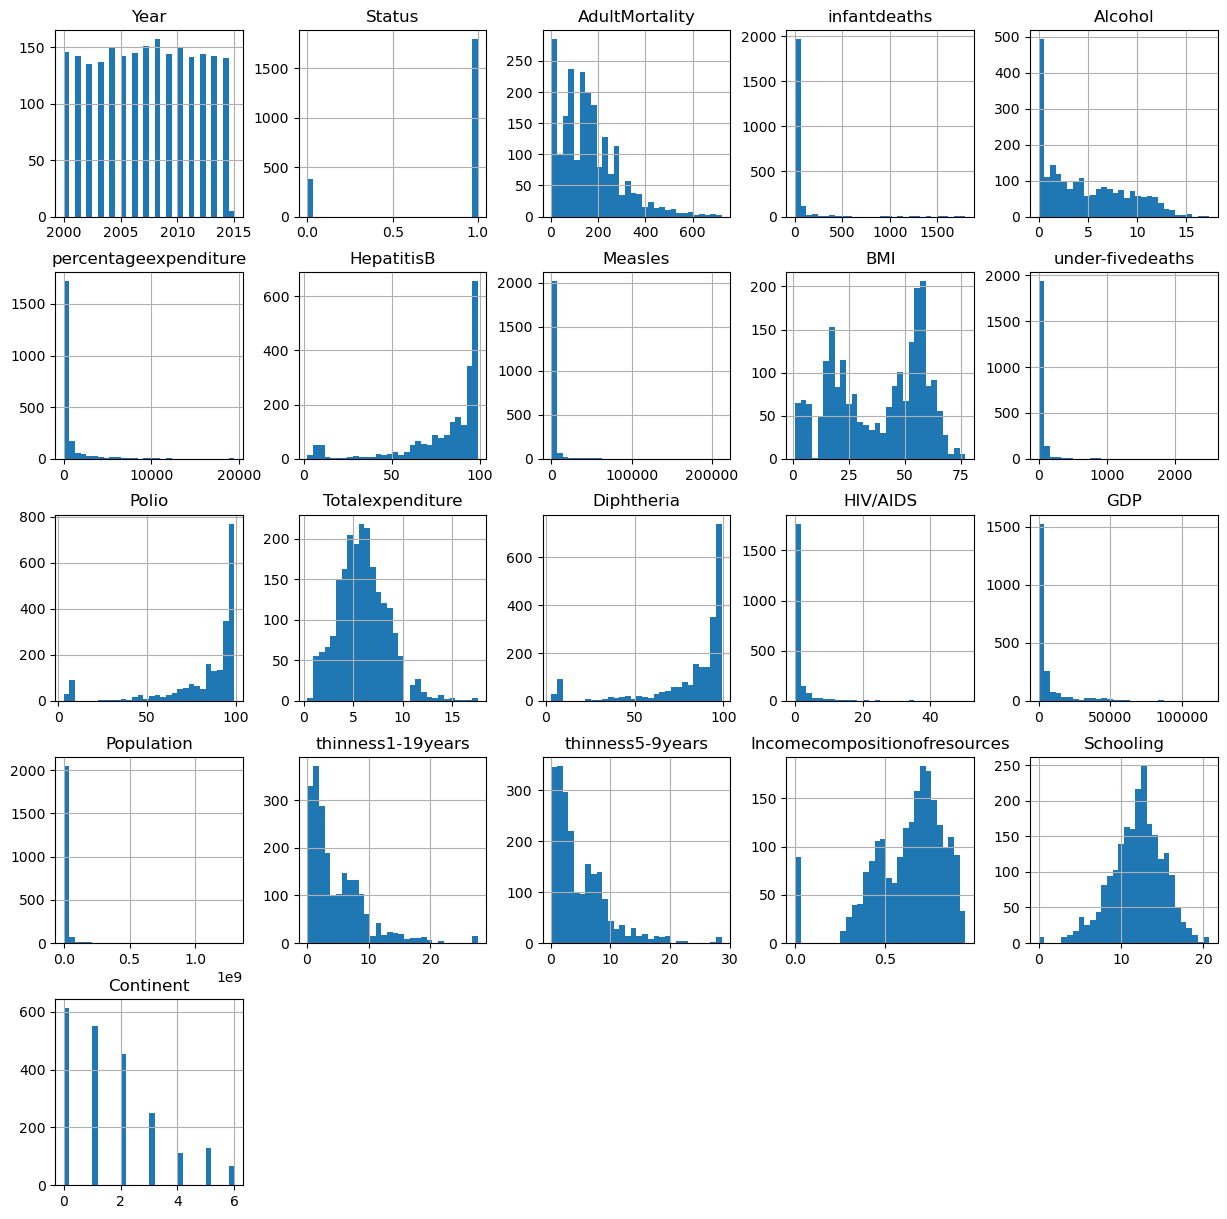

In [22]:
test_data[predictors].hist(bins=30, figsize=(15,15))
plt.show()

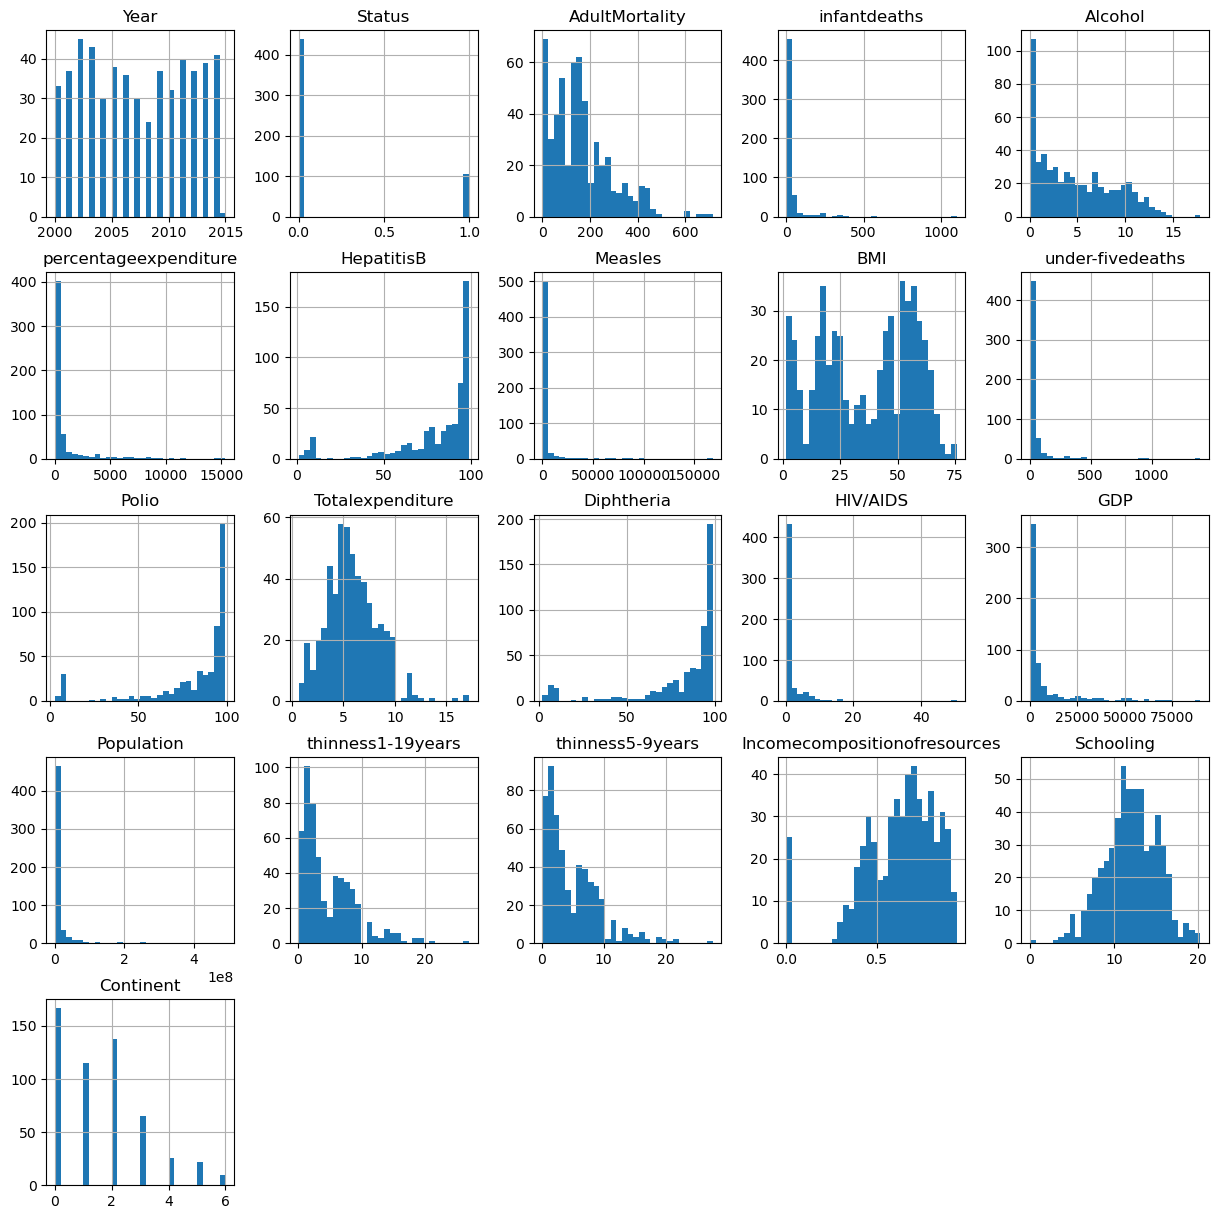

In [23]:
train_data[predictors].hist(bins=30, figsize=(15,15))
plt.show()

In [24]:
# NMW CZEMU NIE DZIAŁA KOD NA WYKRESY PUDEŁKOWE MOŻE ZŁY ZAKRES

def plot_box_strip(train_data, id_variable, hue=None):
    """
    Tworzy wykresy pudełkowe z nakładającymi się wykresami strip dla podanych zmiennych.
    
    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista nazw kolumn dla zmiennych ilościowych
    - hue: opcjonalna zmienna grupująca (kategoryczna)
    """
    for var in id_variable:
        plt.figure(figsize=(8, 6))
        
        # Wykres pudełkowy
        sns.boxplot(data=test_data, y=var, x=hue, fliersize=0, color='green')

        # Wykres strip
        sns.stripplot(data=test_data, y=var, x=hue, jitter=0.1, alpha=0.3, color='k', dodge=True if hue else False)
        
        plt.title(f'Wykres pudełkowy: {var}')
        plt.xlabel(hue if hue else '')
        plt.ylabel(var)
        plt.show()

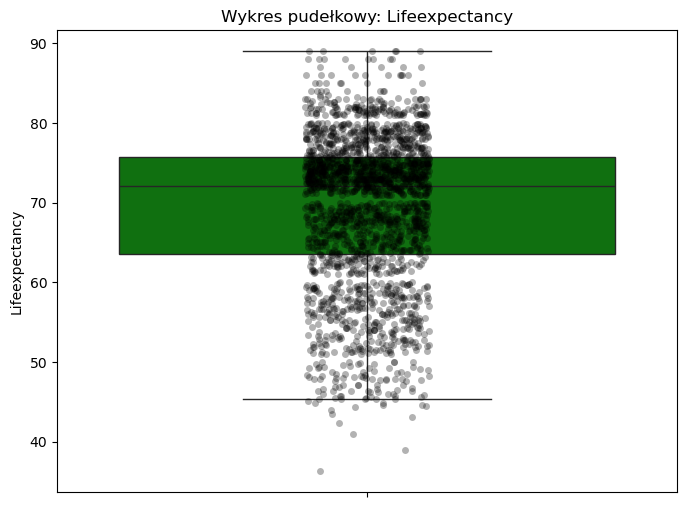

In [25]:
plot_box_strip(test_data, id_variable)

In [26]:
X_train_winsor = train_data.copy()
X_test_winsor = test_data.copy()

In [27]:
predictors_winsor = [
    col for col in predictors
    if col not in ['Country', 'Year', 'Status']
    and train_data[col].nunique() > 5
    and train_data[col].dtype != 'object'
]

In [28]:
# capping_method='iqr' - metoda oparta na rozstępie kwartylowym
# fold=1.5 - parametr sterujacy szerokocią przycinania
# przycinamy z obu stron (dolne i górne outliery)

winsorizer = Winsorizer(capping_method='iqr', fold=1.5, tail='both', variables=predictors_winsor)

X_train_winsor[predictors_winsor] = winsorizer.fit_transform(X_train_winsor[predictors_winsor])
X_test_winsor[predictors_winsor] = winsorizer.transform(X_test_winsor[predictors_winsor])

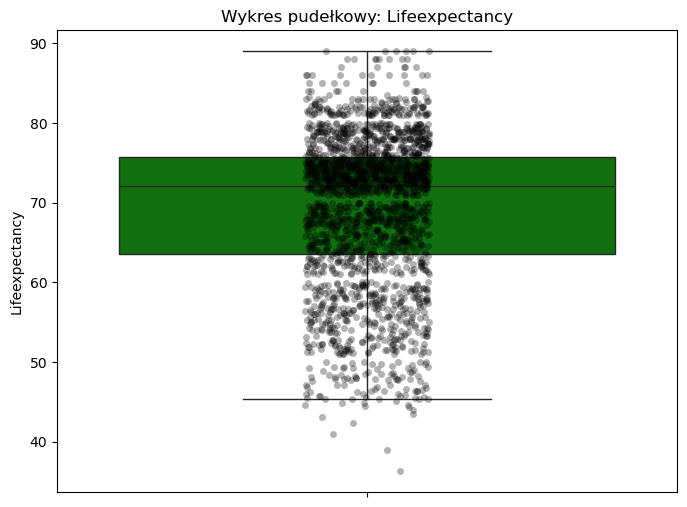

In [29]:
plot_box_strip(X_test_winsor, id_variable)

In [30]:
test_data.describe()

,Year,Status,Lifeexpectancy,AdultMortality,infantdeaths,Alcohol,percentageexpenditure,HepatitisB,Measles,BMI,under-fivedeaths,Polio,Totalexpenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness1-19years,thinness5-9years,Incomecompositionofresources,Schooling,Continent
count,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2.170000e+03,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000
mean,2007.033180,0.825346,69.239631,164.474194,32.050691,4.624995,795.369879,80.881014,2501.278802,38.340000,44.489401,82.709677,5.948029,82.442396,1.782627,6536.669245,1.245834e+07,4.889677,4.892581,0.625750,11.989945,1.694009
std,4.300579,0.379759,9.496080,126.148973,129.441447,4.068294,2089.651964,23.390376,11772.857695,19.787381,176.207415,23.125463,2.470006,23.376677,5.174124,13715.203129,6.168535e+07,4.519115,4.592347,0.205301,3.180267,1.618647
min,2000.000000,0.000000,36.300000,1.000000,0.000000,0.010000,0.000000,2.000000,0.000000,1.000000,0.000000,3.000000,0.370000,3.000000,0.100000,3.685949,4.300000e+01,0.100000,0.100000,0.000000,0.000000,0.000000
25%,2003.000000,1.000000,63.500000,73.000000,0.000000,0.870000,10.816084,75.000000,0.000000,19.300000,0.000000,78.000000,4.300000,78.250000,0.100000,366.784863,3.776358e+05,1.600000,1.500000,0.492000,10.100000,0.000000
50%,2007.000000,1.000000,72.100000,143.000000,3.000000,3.775000,81.080060,91.000000,17.000000,43.650000,4.000000,93.000000,5.800000,93.000000,0.100000,1214.663924,1.867851e+06,3.300000,3.300000,0.674500,12.300000,1.000000
75%,2011.000000,1.000000,75.675000,226.000000,21.000000,7.757500,477.831914,96.000000,371.500000,56.100000,26.750000,97.000000,7.460000,97.000000,0.800000,4791.414543,7.859124e+06,7.200000,7.200000,0.773000,14.100000,3.000000
max,2015.000000,1.000000,89.000000,723.000000,1800.000000,17.310000,19479.911610,99.000000,212183.000000,77.100000,2500.000000,99.000000,17.600000,99.000000,50.300000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000,6.000000


In [31]:
X_test_winsor.describe()

,Year,Status,Lifeexpectancy,AdultMortality,infantdeaths,Alcohol,percentageexpenditure,HepatitisB,Measles,BMI,under-fivedeaths,Polio,Totalexpenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness1-19years,thinness5-9years,Incomecompositionofresources,Schooling,Continent
count,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000,2170.00000,2170.000000,2170.000000,2170.000000,2.170000e+03,2170.000000,2170.000000,2170.000000,2170.000000,2170.000000
mean,2007.033180,0.825346,69.239631,161.106567,12.996774,4.624995,331.512015,83.068479,252.562558,38.340000,16.662097,85.238134,5.92226,84.999078,0.578203,3503.229086,4.983580e+06,4.752097,4.745023,0.628580,12.005567,1.664055
std,4.300579,0.379759,9.496080,115.956054,17.795661,4.068294,454.609148,17.431721,387.202727,19.787381,22.648296,16.041406,2.38578,16.325753,0.777454,4399.773971,6.100128e+06,4.041195,4.072049,0.196958,3.129957,1.546288
min,2000.000000,0.000000,36.300000,1.000000,0.000000,0.010000,0.000000,42.450000,0.000000,1.000000,0.000000,48.250000,0.37000,47.000000,0.100000,3.685949,4.300000e+01,0.100000,0.100000,0.069000,3.400000,0.000000
25%,2003.000000,1.000000,63.500000,73.000000,0.000000,0.870000,10.816084,75.000000,0.000000,19.300000,0.000000,78.000000,4.30000,78.250000,0.100000,366.784863,3.776358e+05,1.600000,1.500000,0.492000,10.100000,0.000000
50%,2007.000000,1.000000,72.100000,143.000000,3.000000,3.775000,81.080060,91.000000,17.000000,43.650000,4.000000,93.000000,5.80000,93.000000,0.100000,1214.663924,1.867851e+06,3.300000,3.300000,0.674500,12.300000,1.000000
75%,2011.000000,1.000000,75.675000,226.000000,21.000000,7.757500,477.831914,96.000000,371.500000,56.100000,26.750000,97.000000,7.46000,97.000000,0.800000,4791.414543,7.859124e+06,7.200000,7.200000,0.773000,14.100000,3.000000
max,2015.000000,1.000000,89.000000,453.250000,50.000000,17.310000,1314.185221,99.000000,993.750000,77.100000,61.250000,99.000000,12.26000,99.000000,2.100000,12719.701543,1.749616e+07,15.875000,16.100000,0.948000,20.700000,5.000000


In [32]:
X_train = X_train_winsor[predictors]
y_train = X_train_winsor[id_variable[0]]

X_test = X_test_winsor[predictors]
y_test = X_test_winsor[id_variable[0]]

In [33]:
# Model regresji liniowej
model = LinearRegression()
model.fit(X_train, y_train)

# Predykcje
y_pred = model.predict(X_test)

In [34]:
# Metryki oceny
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
nrmse = rmse / (y_test.max() - y_test.min()) * 100  # NRMSE w %

print(f"R²: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"NRMSE: {nrmse:.2f}%")

R²: 0.7943
RMSE: 4.3060
NRMSE: 8.17%


In [35]:
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
nrmse_rf = rmse_rf / (y_test.max() - y_test.min()) * 100

print(f"Random Forest — R²: {r2_rf:.4f}")
print(f"Random Forest — RMSE: {rmse_rf:.4f}")
print(f"Random Forest — NRMSE: {nrmse_rf:.2f}%")

Random Forest — R²: 0.9226
Random Forest — RMSE: 2.6407
Random Forest — NRMSE: 5.01%


In [36]:
#Tuning hiperparametrów
model_rf = RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42)
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
nrmse_rf = rmse_rf / (y_test.max() - y_test.min()) * 100

print(f"Random Forest — R²: {r2_rf:.4f}")
print(f"Random Forest — RMSE: {rmse_rf:.4f}")
print(f"Random Forest — NRMSE: {nrmse_rf:.2f}%")

Random Forest — R²: 0.9228
Random Forest — RMSE: 2.6372
Random Forest — NRMSE: 5.00%


Dalej brakuje do R² > 94

In [37]:
model_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42
)

model_xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.9, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [38]:
y_pred_xgb = model_xgb.predict(X_test)

r2 = r2_score(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
nrmse = rmse / y_test.mean() * 100

print(f"XGBoost — R²: {r2:.4f}")
print(f"XGBoost — RMSE: {rmse:.4f}")
print(f"XGBoost — NRMSE: {nrmse:.2f}%")

XGBoost — R²: 0.9275
XGBoost — RMSE: 2.5571
XGBoost — NRMSE: 3.69%


In [39]:
# Model bazowy
xgb = XGBRegressor(random_state=42)

# Zakres hiperparametrów do sprawdzenia
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}

# GridSearch z 3-krotną walidacją krzyżową
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    verbose=2,
    n_jobs=-1
)

In [40]:
# Uruchomienie strojenia
grid_search.fit(X_train, y_train)

# Najlepsze parametry
print("Best params:", grid_search.best_params_)

Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best params: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.7}


In [41]:
# Model z najlepszymi parametrami
best_model = grid_search.best_estimator_

# Ewaluacja na zbiorze testowym
y_pred = best_model.predict(X_test)

In [42]:
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
nrmse = rmse / y_test.mean() * 100

print(f"Tuned XGBoost — R²: {r2:.4f}")
print(f"Tuned XGBoost — RMSE: {rmse:.4f}")
print(f"Tuned XGBoost — NRMSE: {nrmse:.2f}%")

Tuned XGBoost — R²: 0.9275
Tuned XGBoost — RMSE: 2.5564
Tuned XGBoost — NRMSE: 3.69%


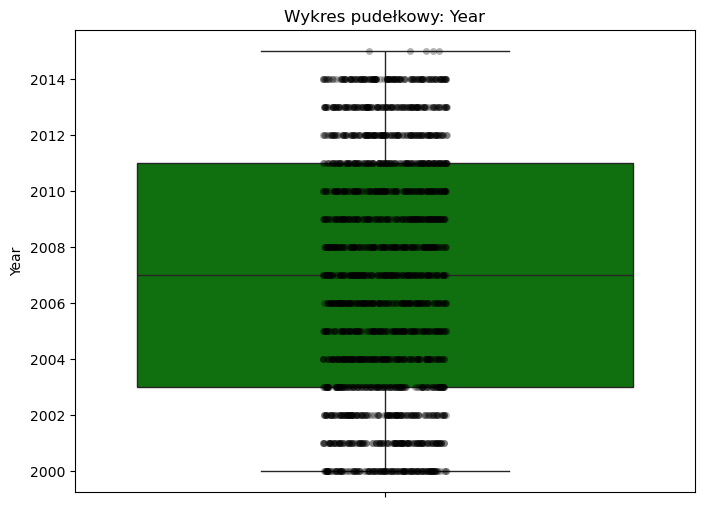

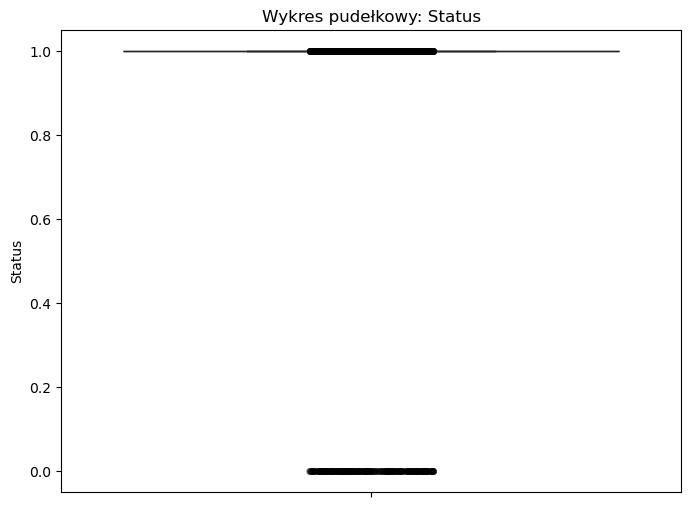

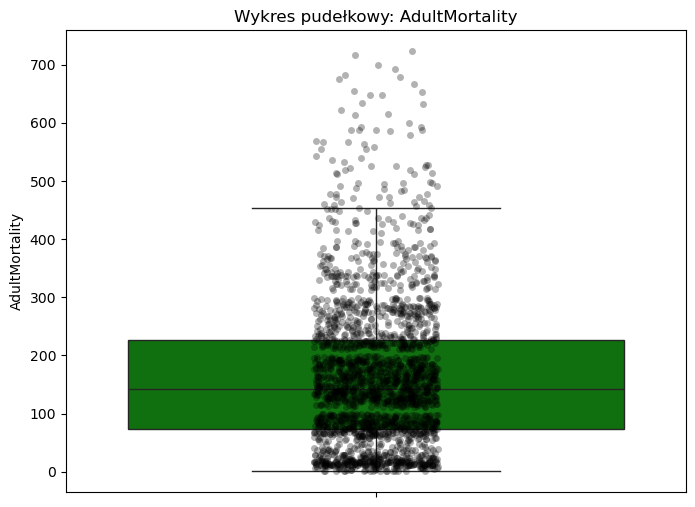

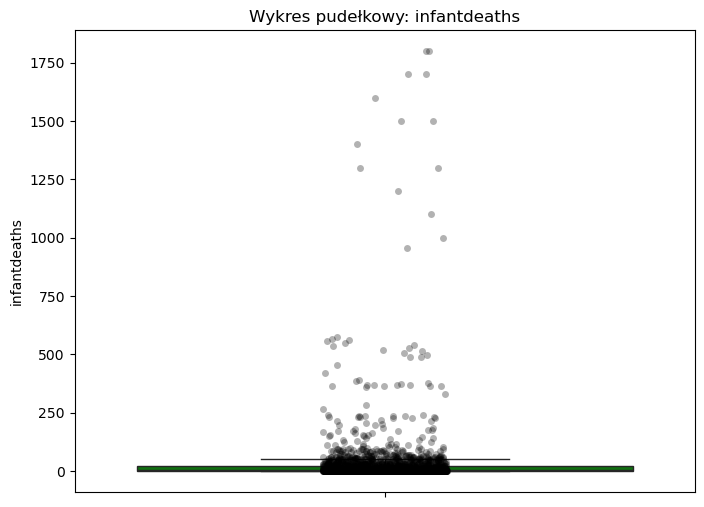

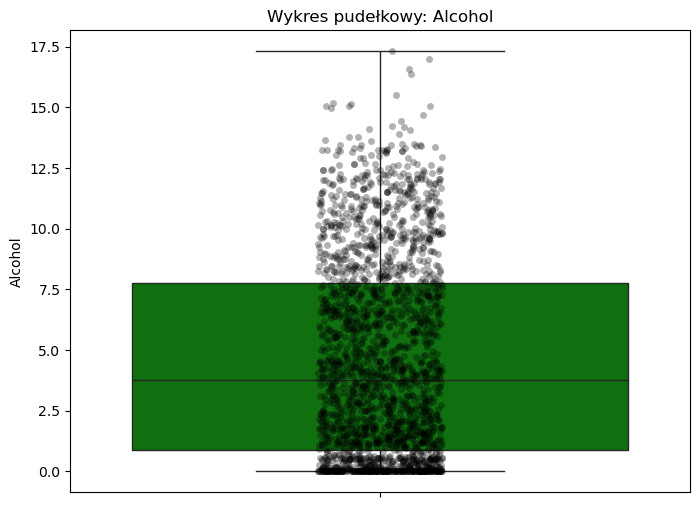

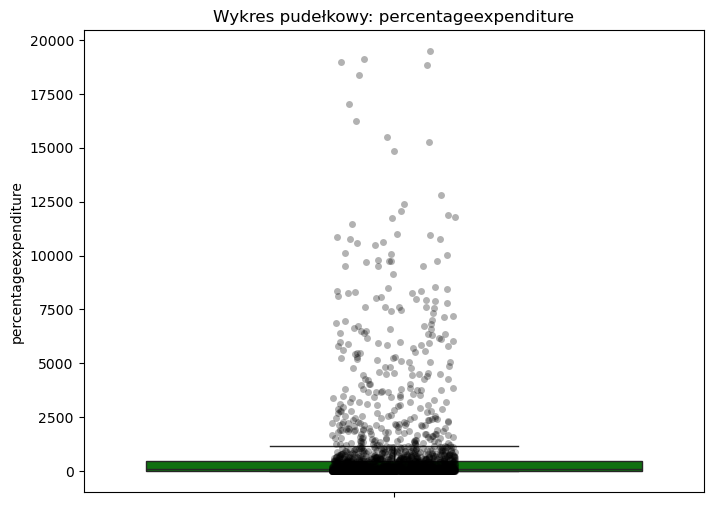

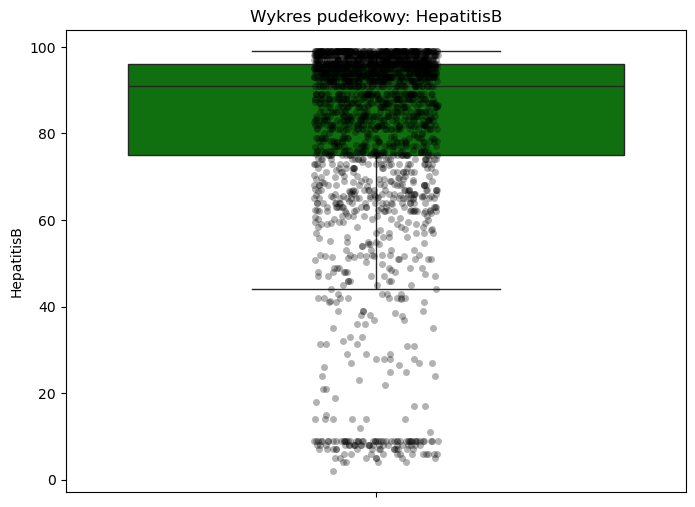

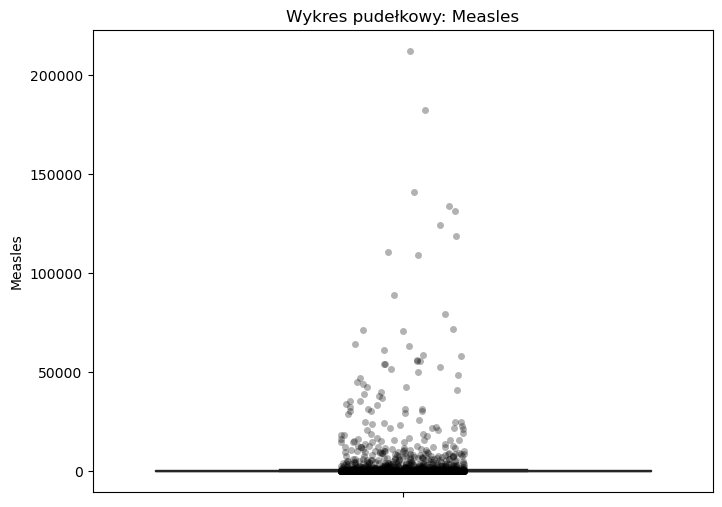

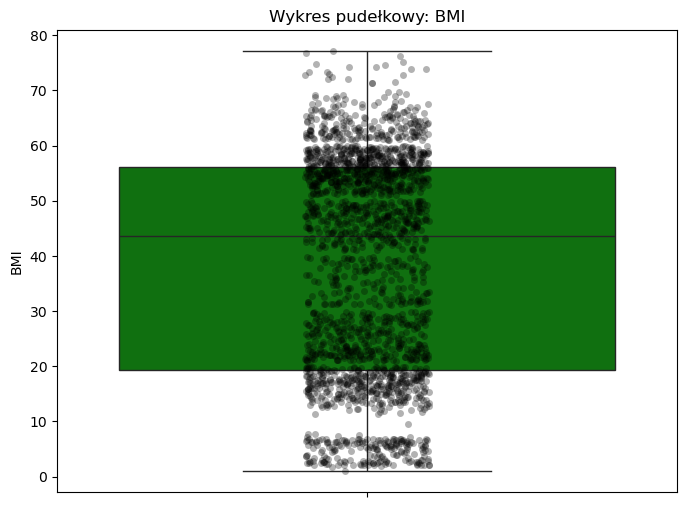

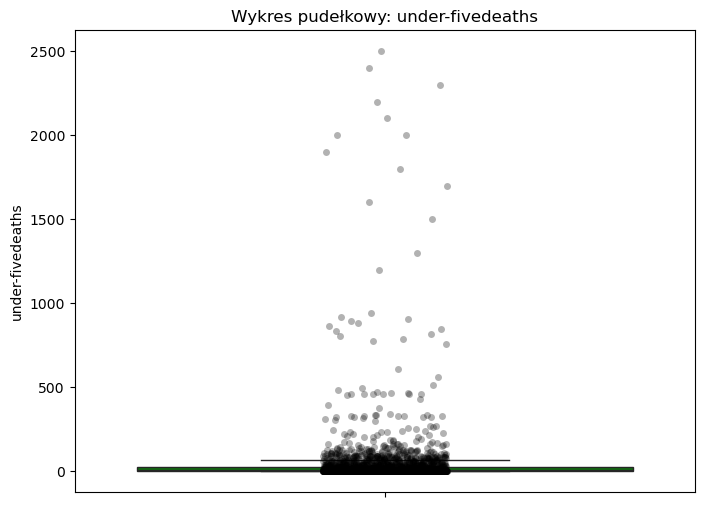

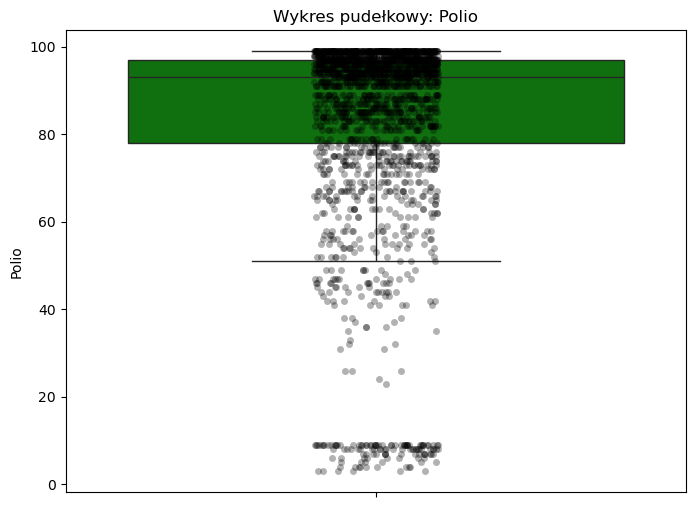

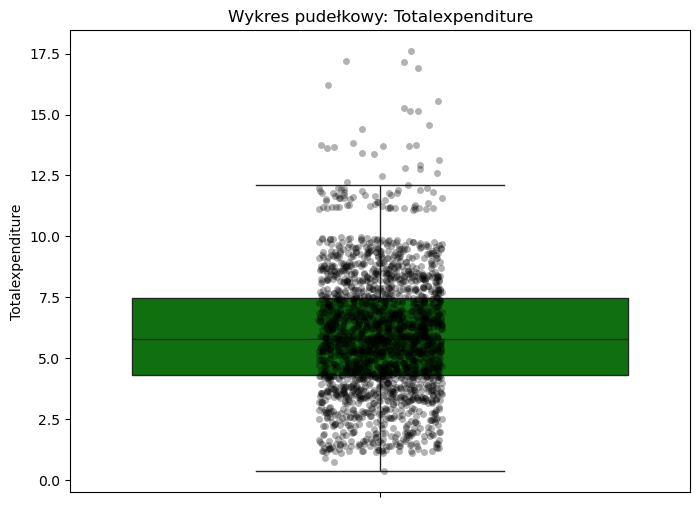

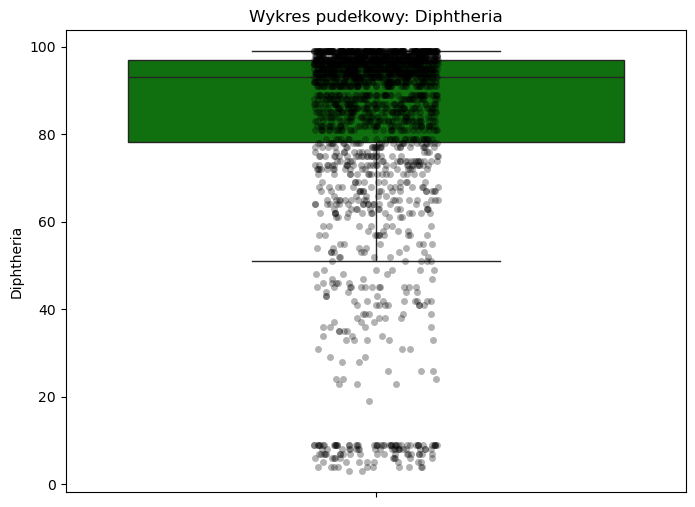

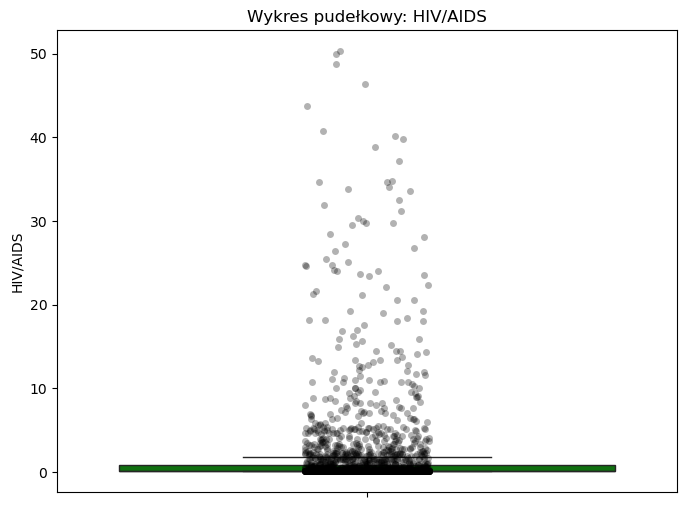

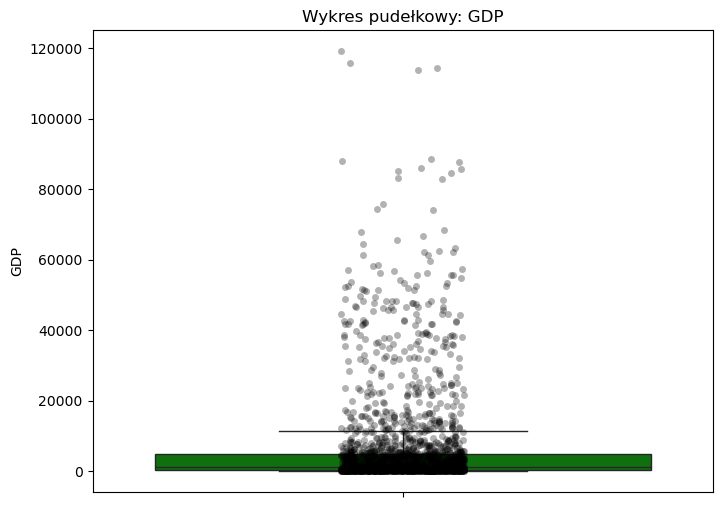

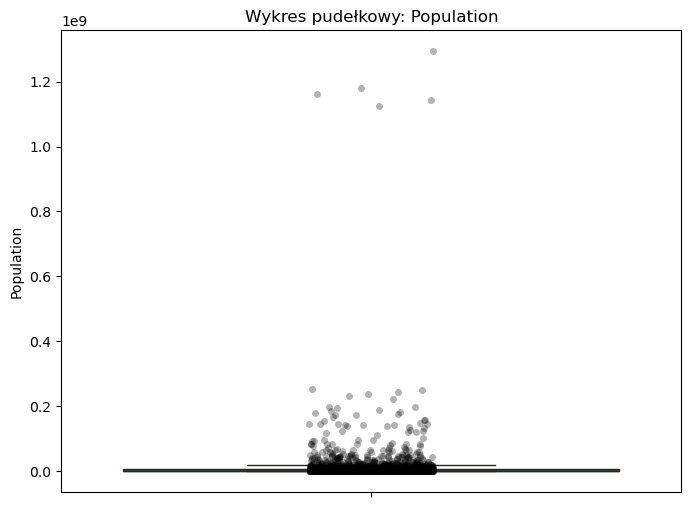

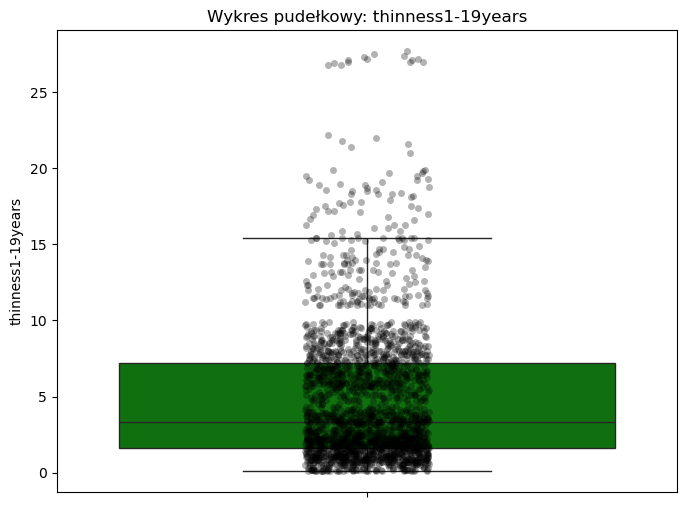

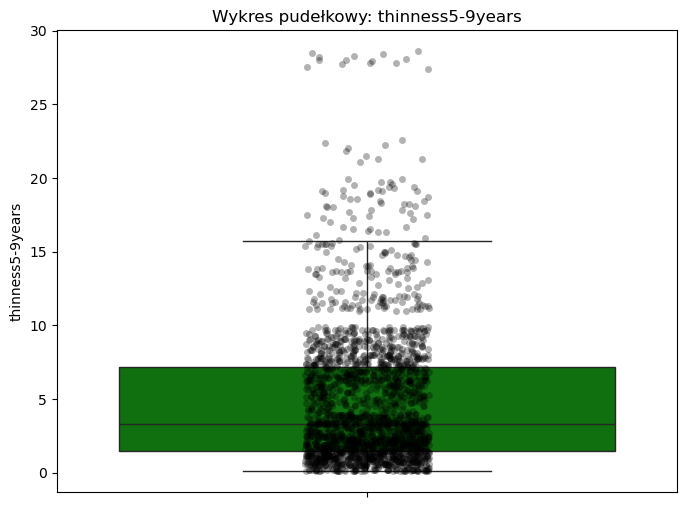

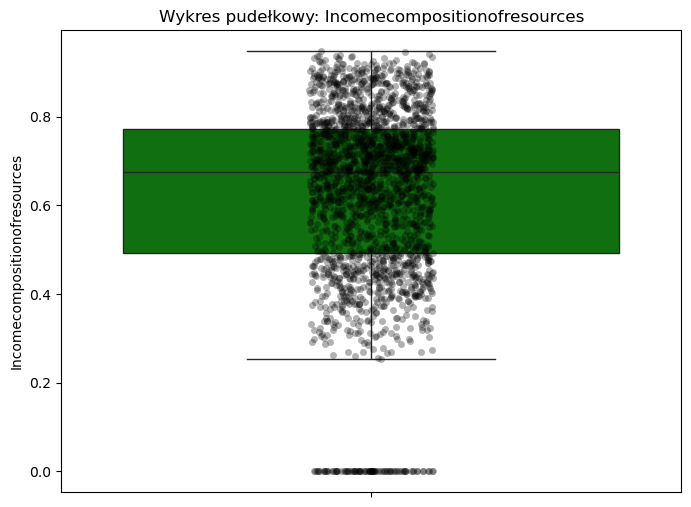

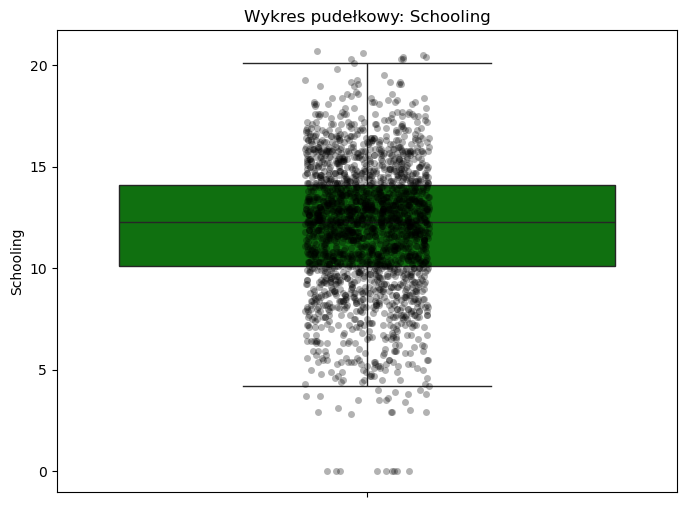

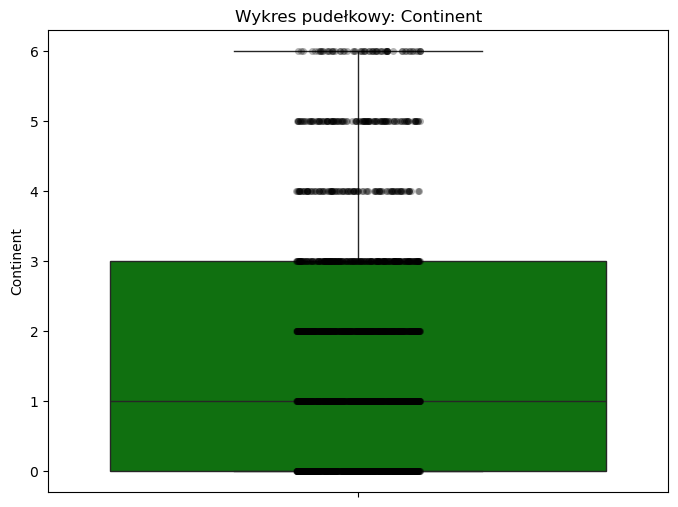

In [43]:
# Wykresy ramka-wąsy analiza pod kątem wartości odstających
plot_box_strip(test_data,predictors)


In [44]:
# --- 0. Ustawienie seedów dla powtarzalności ---
random.seed(42)
np.random.seed(42)

# --- 1. Łączenie danych wejściowych i targetu ---
X_y_train = X_train.copy()
X_y_train['target'] = y_train

# --- 2. Funkcja przycinająca wartości odstające (winsoryzacja) metodą IQR ---
def winsorize_iqr(df, features):
    df_copy = df.copy()
    for col in features:
        Q1 = df_copy[col].quantile(0.25)
        Q3 = df_copy[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_copy[col] = df_copy[col].clip(lower, upper)
    return df_copy

# --- 3. Winsoryzacja tylko na cechach (nie na targetcie) ---
features_to_winsorize = list(X_train.columns)
X_y_winsorized = winsorize_iqr(X_y_train, features_to_winsorize)

# --- 4. Podział z powrotem na cechy i target ---
X_train_winsorized = X_y_winsorized.drop(columns=['target'])
y_train_winsorized = X_y_winsorized['target']

print(f"Liczba obserwacji przed i po winsoryzacji: {len(X_train)} (nic nie tracimy!)")

# --- 5. Uczenie modelu na danych po winsoryzacji ---
best_model = XGBRegressor(
    colsample_bytree=0.7,
    learning_rate=0.05,
    max_depth=6,
    n_estimators=300,
    subsample=0.7,
    random_state=42
)

best_model.fit(X_train_winsorized, y_train_winsorized)

# --- 6. Predykcja i ocena na danych testowych ---
y_pred = best_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
nrmse = rmse / y_test.mean() * 100

print(f"\n📊 Po winsoryzacji (zachowano wszystkie dane):")
print(f"Tuned XGBoost (winsorized) - R²: {r2:.4f}")
print(f"Tuned XGBoost (winsorized) - RMSE: {rmse:.4f}")
print(f"Tuned XGBoost (winsorized) - NRMSE: {nrmse:.2f}%")



Liczba obserwacji przed i po winsoryzacji: 543 (nic nie tracimy!)

📊 Po winsoryzacji (zachowano wszystkie dane):
Tuned XGBoost (winsorized) - R²: 0.9320
Tuned XGBoost (winsorized) - RMSE: 2.4753
Tuned XGBoost (winsorized) - NRMSE: 3.57%


In [45]:
# Sprawdzenie zgodności cech w X_test
print("Brakujące kolumny w X_test:", set(X_train_winsorized.columns) - set(X_test.columns))



Brakujące kolumny w X_test: set()


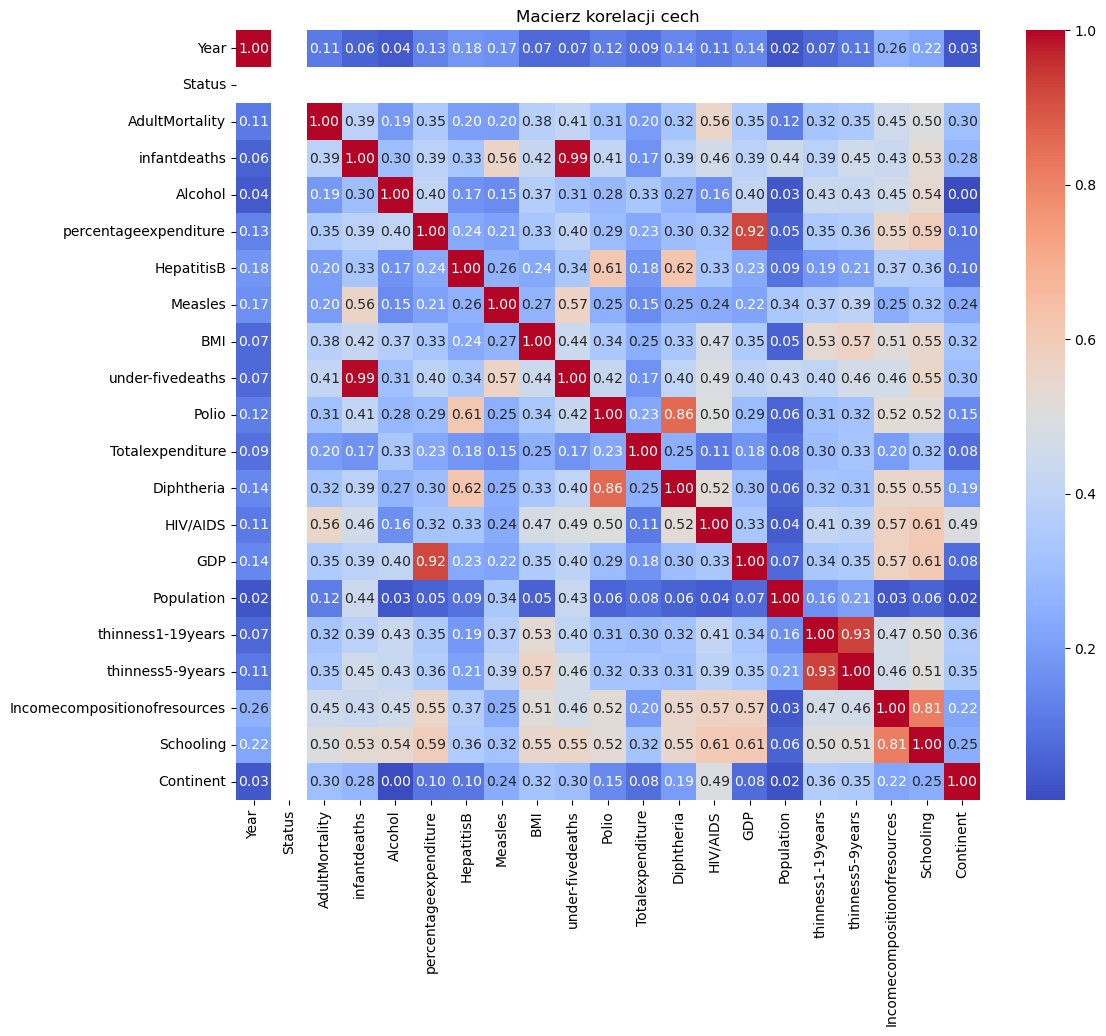

In [46]:

# Liczymy korelację na danych treningowych (po winsoryzacji)
corr_matrix = X_train_winsorized.corr().abs()

# Wizualizacja
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Macierz korelacji cech")
plt.show()


In [47]:
print("Kolumny X_train_winsorized:")
print(X_train_winsorized.columns.tolist())


Kolumny X_train_winsorized:
['Year', 'Status', 'AdultMortality', 'infantdeaths', 'Alcohol', 'percentageexpenditure', 'HepatitisB', 'Measles', 'BMI', 'under-fivedeaths', 'Polio', 'Totalexpenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness1-19years', 'thinness5-9years', 'Incomecompositionofresources', 'Schooling', 'Continent']


In [48]:
print("Nazwa kolumny y_test:")
print(y_test.name)


Nazwa kolumny y_test:
Lifeexpectancy


In [49]:
# Usuwamy zduplikowane kolumny — zachowujemy tylko pierwsze wystąpienie
X_train_winsorized = X_train_winsorized.loc[:, ~X_train_winsorized.columns.duplicated()]
X_test = X_test.loc[:, ~X_test.columns.duplicated()]


In [50]:
# Eliminujemy jedną cechę z każdej pary z korelacją powyżej 0.95
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.95)]

print(f"Cechy do usunięcia: {to_drop}")
X_train_reduced = X_train_winsorized.drop(columns=to_drop)
X_test_reduced = X_test.drop(columns=to_drop)


Cechy do usunięcia: ['under-fivedeaths']


In [51]:
#  Uczenie modelu na danych po redukcji cech ---
best_model = XGBRegressor(
    colsample_bytree=0.7,
    learning_rate=0.05,
    max_depth=6,
    n_estimators=300,
    subsample=0.7,
    random_state=42
)

best_model.fit(X_train_reduced, y_train_winsorized)

# --- 6. Predykcja i ocena na danych testowych po redukcji ---
y_pred = best_model.predict(X_test_reduced)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
nrmse = rmse / y_test.mean() * 100

print(f"\n📊 Po winsoryzacji + usunięciu skorelowanych cech:")
print(f"Tuned XGBoost (reduced) - R²: {r2:.4f}")
print(f"Tuned XGBoost (reduced) - RMSE: {rmse:.4f}")
print(f"Tuned XGBoost (reduced) - NRMSE: {nrmse:.2f}%")



📊 Po winsoryzacji + usunięciu skorelowanych cech:
Tuned XGBoost (reduced) - R²: 0.9328
Tuned XGBoost (reduced) - RMSE: 2.4619
Tuned XGBoost (reduced) - NRMSE: 3.56%


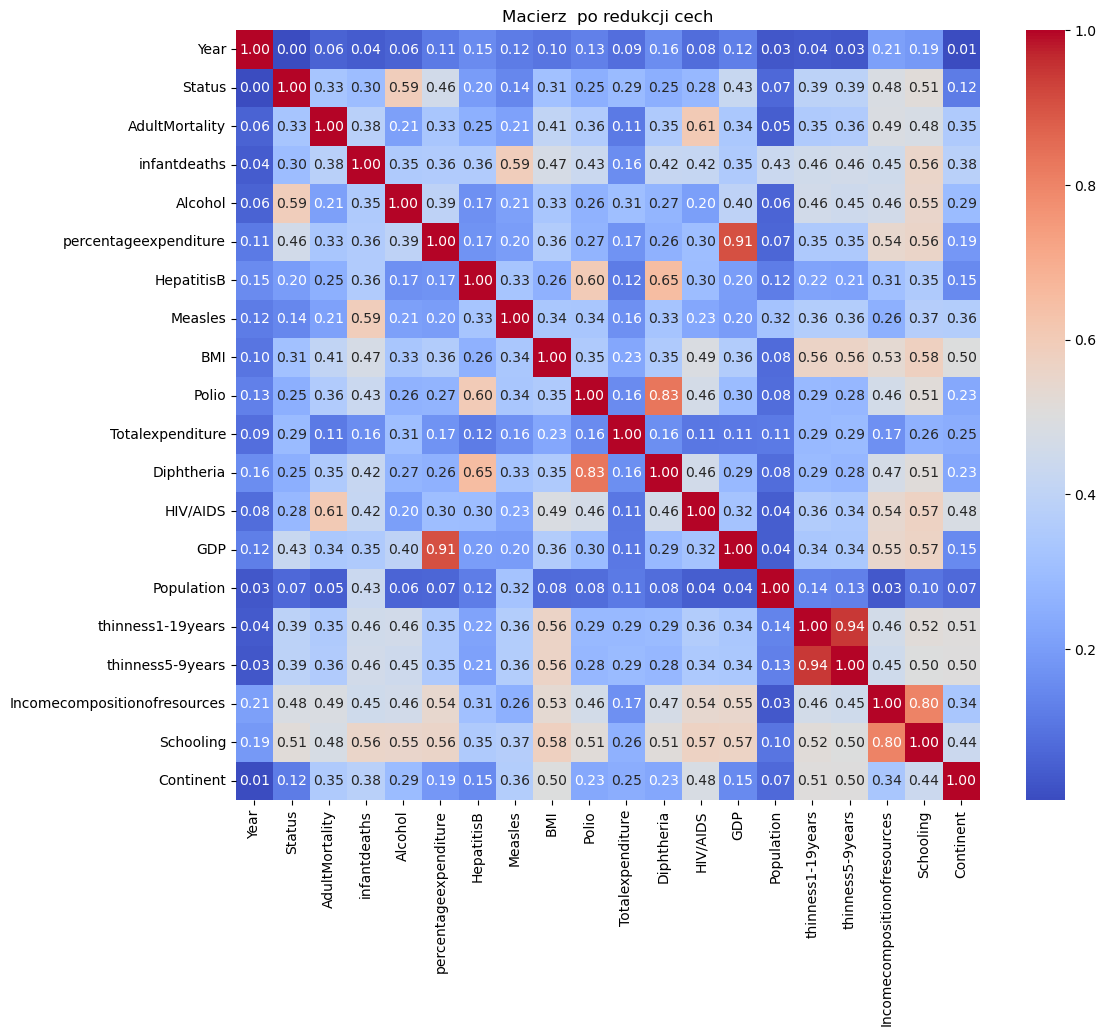

In [52]:
# Liczymy korelację na danych treningowych ( po redukcji cech)
corr_matrix = X_test_reduced.corr().abs()

# Wizualizacja
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Macierz  po redukcji cech")
plt.show()


Top 10 cech wg średniego gain:
                         feature        gain
11                      HIV/AIDS  725.050598
18                     Continent  168.436081
16  Incomecompositionofresources  136.700806
17                     Schooling   82.289856
1                 AdultMortality   26.648865
15              thinness5-9years   18.781717
2                   infantdeaths   14.549547
8                          Polio    9.496360
10                    Diphtheria    8.728340
7                            BMI    8.056862


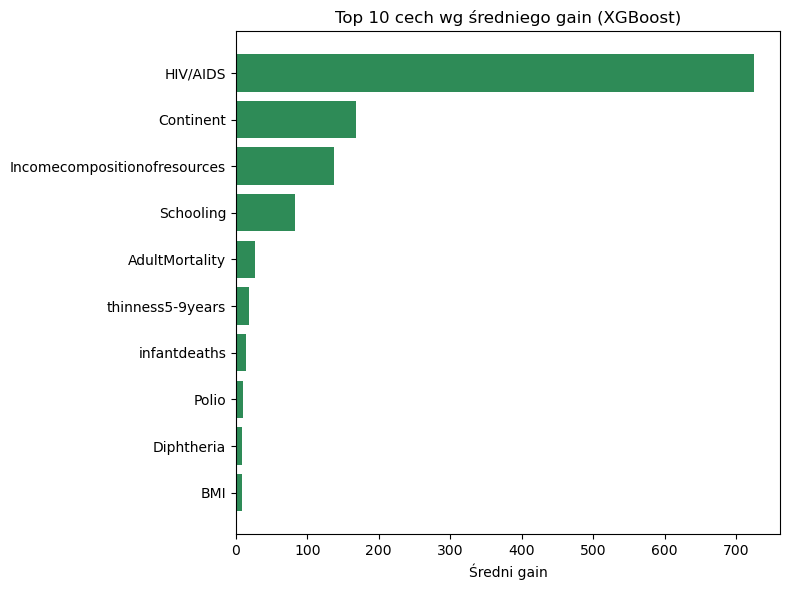

In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Pobranie booster-a
booster = best_model.get_booster()

# 2. Słownik importancji (tu wg “gain”, możesz też użyć 'weight', 'cover', 'total_gain', 'total_cover')
importance_dict = booster.get_score(importance_type='gain')

# 3. Zamiana na DataFrame i sortowanie malejąco
imp_df = (
    pd.DataFrame.from_dict(importance_dict, orient='index', columns=['gain'])
      .reset_index()
      .rename(columns={'index':'feature'})
      .sort_values('gain', ascending=False)
)

# 4. Wyświetlenie top 10 cech
print("Top 10 cech wg średniego gain:")
print(imp_df.head(10))

# 5. Wykres słupkowy
top_n = 10
plt.figure(figsize=(8,6))
plt.barh(
    imp_df['feature'].head(top_n)[::-1],
    imp_df['gain'].head(top_n)[::-1],
    color='seagreen'
)
plt.title('Top 10 cech wg średniego gain (XGBoost)')
plt.xlabel('Średni gain')
plt.tight_layout()
plt.show()



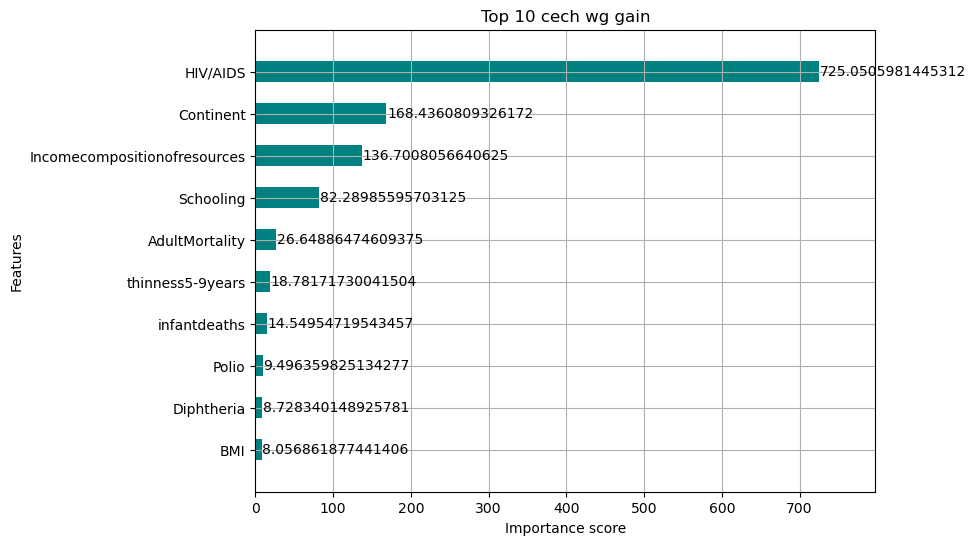

In [54]:
import xgboost as xgb

# Pokazuje domyślnie wg “weight” – zmień importance_type='gain' jeśli potrzebujesz
ax = xgb.plot_importance(
    booster,
    importance_type='gain',
    max_num_features=10,
    height=0.5,
    color='teal'
)
ax.figure.set_size_inches(8, 6)
ax.set_title('Top 10 cech wg gain')
plt.show()



In [ ]:




#  1. HIV/AIDS – zdecydowanie najważniejsza zmienna

#     Najwyższy średni gain (ponad 700) – dominujący wpływ na długość życia.

#     Wysoki wskaźnik HIV/AIDS silnie koreluje z niższą długością życia, szczególnie w krajach rozwijających się.

#     Ma największą moc predykcyjną w modelu XGBoost.

#  2. Continent – istotny czynnik geograficzny

#     Wpływ kontynentu sugeruje, że uwarunkowania regionalne (np. infrastruktura, klimat, kultura zdrowotna) mają znaczenie.

#     Model uczy się, że długość życia istotnie różni się np. między Afryką a Europą.

# 3. Income Composition of Resources

#     Wskaźnik reprezentujący dostępność zasobów dla obywateli (np. zatrudnienie, opieka społeczna).

#     Wysoka wartość tego wskaźnika = wyższa jakość życia i zdrowia → dłuższe życie.

# 4. Schooling – lata edukacji

#     Edukacja przekłada się na świadomość zdrowotną, lepsze decyzje dotyczące stylu życia i korzystania z opieki zdrowotnej.

#     Silna korelacja z oczekiwaną długością życia.
#  5. Adult Mortality – śmiertelność dorosłych

#     Negatywnie wpływa na oczekiwaną długość życia.

#     Mimo że intuicyjnie bardzo ważna, ma niższy gain niż czynniki systemowe jak HIV/AIDS czy edukacja.

# Pozostałe czynniki:

#     thinness 5-9 years – pośredni wskaźnik stanu odżywienia, ważny w krajach rozwijających się.

#     infant deaths – śmiertelność niemowląt również wpływa na średnią długość życia.

#     Polio, Diphtheria – status szczepień jako proxy dla systemu opieki zdrowotnej.

#     BMI – stan zdrowia populacji, wpływa na choroby cywilizacyjne (cukrzyca, choroby serca).

# Model XGBoost potwierdza, że czynniki zdrowotne (HIV/AIDS, szczepienia), systemowe (edukacja, dostęp do zasobów) i geograficzne (kontynent) są najważniejsze w przewidywaniu długości życia.

# HIV/AIDS jest zdecydowanie najważniejszym pojedynczym czynnikiem.

# Wpływ BMI, szczepień i śmiertelności niemowląt potwierdza znaczenie profilaktyki zdrowotnej.


# Rekomendacje na podstawie analizy

#     Inwestycje w walkę z HIV/AIDS mają największy potencjalny wpływ na wydłużenie życia w krajach z wysoką zachorowalnością.

#     Poprawa edukacji i dostęp do zasobów są kluczowe dla rozwoju zdrowotnego społeczeństw.

#     Geograficzne różnice powinny być uwzględniane w politykach zdrowotnych (np. działania dostosowane do kontynentu).

#     Profilaktyka i szczepienia – kontynuacja i rozwój programów szczepień (np. Polio, Diphtheria) oraz monitorowanie BMI i żywienia dzieci.

































Pozytywne korelacje z Life Expectancy (przypuszczalne, na podstawie logicznej analizy i korelacji z innymi cechami):

    Schooling – wyższy poziom edukacji → wyższa długość życia

    Incomecompositionofresources – lepszy dostęp do zasobów → lepsze zdrowie

    Totalexpenditure – większe wydatki zdrowotne → lepsza opieka medyczna

    GDP – bogatsze kraje mają wyższe wskaźniki zdrowia

❌ Negatywne korelacje z Life Expectancy:

    AdultMortality – wyższa śmiertelność dorosłych → krótsza długość życia

    HIV/AIDS – wyższy wskaźnik → obniża długość życia

    infantdeaths – większa śmiertelność noworodków → niższa średnia życia

Zmienność w oczekiwanej długości życia jest silnie zależna od czynników społeczno-ekonomicznych i zdrowotnych.

Największy wpływ mają: HIV/AIDS, GDP, dostęp do edukacji, opieka zdrowotna, infant mortality.